# Session 6 demo, Part C: the Challenger launch

Build the logistic model the engineers didn't build, on the **23 shuttle flights before Challenger**. Each flight has its launch temperature and whether an O-ring showed damage. The forecast for launch morning was 31F. Runs in Colab with nothing to upload.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

ch = pd.DataFrame({
    'temp_f': [66,70,69,68,67,72,73,70,57,63,70,78,67,53,67,75,70,81,76,79,75,76,58],
    'damage': [0,1,0,0,0,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,1,0,1],
})
print(f"{len(ch)} flights, {int(ch.damage.sum())} with O-ring damage, coldest {int(ch.temp_f.min())}F")
ch.head()

23 flights, 7 with O-ring damage, coldest 53F


,temp_f,damage
0,66,0
1,70,1
2,69,0
3,68,0
4,67,0


**Predict first.** The seals were only ever tested down to about 53F. The forecast is 31F. From these 23 flights, how likely is O-ring damage at 31F? Commit to a number before you fit the model.

In [2]:
# Logistic regression: P(damage) as a function of temperature
m = sm.Logit(ch['damage'], sm.add_constant(ch['temp_f'])).fit(disp=0)
p31 = float(m.predict([[1, 31]])[0])
odds_ratio_10 = float(np.exp(-10 * m.params['temp_f']))
print(f"P(damage at 31F) = {p31:.4f}")
print(f"Every 10F colder multiplies the odds of damage by about {odds_ratio_10:.0f}x")

P(damage at 31F) = 0.9996
Every 10F colder multiplies the odds of damage by about 10x


The model puts the chance of O-ring damage at 31F at **over 0.99**: near-certain. The honest caveat: 31F is well below any flight on record, so this is extrapolation. Every reasonable reading still says the same thing.

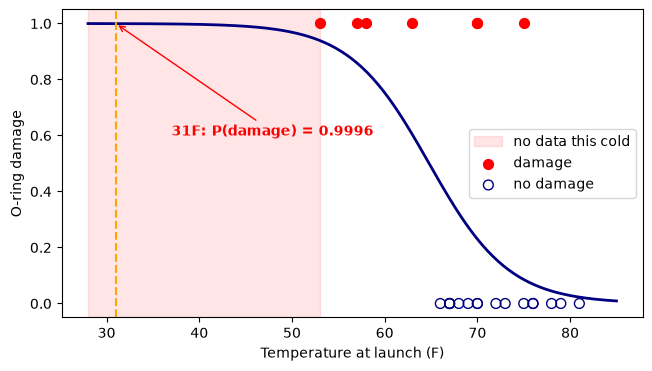

In [3]:
xs = np.linspace(28, 85, 300)
ps = m.predict(sm.add_constant(xs))
plt.figure(figsize=(7.5, 4))
plt.axvspan(28, 53, color='red', alpha=0.1, label='no data this cold')
plt.scatter(ch.temp_f[ch.damage==1], ch.damage[ch.damage==1], color='red', s=50, label='damage')
plt.scatter(ch.temp_f[ch.damage==0], ch.damage[ch.damage==0], facecolors='none',
            edgecolors='navy', s=50, label='no damage')
plt.plot(xs, ps, 'navy', lw=2)
plt.axvline(31, color='orange', ls='--')
plt.annotate(f'31F: P(damage) = {p31:.4f}', xy=(31, p31), xytext=(37, 0.6),
             arrowprops=dict(arrowstyle='->', color='red'), color='red', fontweight='bold')
plt.xlabel('Temperature at launch (F)'); plt.ylabel('O-ring damage'); plt.legend(); plt.show()

## How sure is 0.9996? (the third question)

Redraw the 23 flights with replacement 2,000 times and refit, the same bootstrap idea as Session 3. How low does the 31F prediction ever get?

In [4]:
rng = np.random.default_rng(0)
preds = []
for _ in range(2000):
    b = ch.sample(len(ch), replace=True, random_state=int(rng.integers(1_000_000_000)))
    if b.damage.nunique() < 2:
        continue
    try:
        bf = sm.Logit(b['damage'], sm.add_constant(b['temp_f'])).fit(disp=0, maxiter=200)
        preds.append(float(bf.predict([[1, 31]])[0]))
    except Exception:
        pass
lo = np.percentile(preds, 2.5)
print(f"In {len(preds)} refits, 97.5% put P(damage at 31F) at {lo:.2f} or higher.")
print('Even the cautious end of the range says: do not fly.')

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

...

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

In 1999 refits, 97.5% put P(damage at 31F) at 0.91 or higher.
Even the cautious end of the range says: do not fly.


/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0/JquTurcIhqIOdBmm/lib/python3.14/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Users/eoinlane/.cache/uv/archive-v0

## Write the memo

> *The forecast is 31F at launch. Using the flight data, recommend LAUNCH or DELAY in one paragraph a non-technical manager can act on. Cite your model.*

Lead with the decision. Translate the number into plain English (near-certain seal damage). State the uncertainty honestly (extrapolation, and the bootstrap range above). This is the skill the module assesses: turning model output into a written recommendation.

### The dark twin of John Snow

The data was there that night. The chart the engineers argued over showed only the flights **with** damage, so the temperature pattern vanished, the opposite of John Snow, who counted the cases where nothing happened. A clear logistic model on **all** the flights, and the habit of plotting every point, would have made the 31F risk hard to miss.